# Session 6 – Naive Bayes Classification
## Practical lab: Spam detection, probabilities and text classification

### Learning objectives
By the end of this notebook, you should be able to:
1. Explain prior, likelihood and posterior probability.
2. Understand the conditional independence assumption.
3. Build a text classifier using Bag-of-Words and Multinomial Naive Bayes.
4. Understand Laplace smoothing and why it matters.
5. Compare Multinomial, Bernoulli, Gaussian and Categorical Naive Bayes.
6. Evaluate a classifier using a confusion matrix, precision, recall and F1-score.

### Dataset
The main exercise uses a small, self-contained illustrative email dataset. It is designed for classroom learning and is not a benchmark dataset. Later sections use built-in scikit-learn datasets to demonstrate other Naive Bayes variants.


## 1. The idea: classify an email as Spam or Ham

Naive Bayes is a supervised probabilistic learning algorithm. It uses Bayes' theorem to estimate the probability of a class given observed features.

- **Spam:** unwanted or promotional email.
- **Ham:** legitimate email.

The classifier estimates the probability of each class and predicts the class with the highest posterior probability.

### Bayes' theorem

For a class C and observed features X:

\[
P(C\mid X)=\frac{P(X\mid C)P(C)}{P(X)}
\]

- **Prior** P(C): probability of a class before looking at the message.
- **Likelihood** P(X|C): probability of observing the message features in that class.
- **Evidence** P(X): overall probability of observing those features.
- **Posterior** P(C|X): updated probability of the class after observing the features.

For classification, P(X) is the same across classes, so we compare P(X|C) × P(C).


## 2. A small probability example

Suppose a training collection contains 100 messages:
- 40 Spam messages
- 60 Ham messages

Then:
- P(Spam) = 40/100 = 0.40
- P(Ham) = 60/100 = 0.60

The prior says that before reading a new message, Spam has a 40% probability in this example.

Now suppose the word `free` appears in 30 of the 40 Spam messages and 3 of the 60 Ham messages:
- P(free | Spam) = 30/40 = 0.75
- P(free | Ham) = 3/60 = 0.05

For a message containing `free`, the unnormalized scores are:
- Spam: 0.40 × 0.75 = 0.30
- Ham: 0.60 × 0.05 = 0.03

Normalize these scores to obtain posterior probabilities.


In [1]:
prior_spam = 0.40
prior_ham = 0.60
p_free_given_spam = 0.75
p_free_given_ham = 0.05

score_spam = prior_spam * p_free_given_spam
score_ham = prior_ham * p_free_given_ham

posterior_spam = score_spam / (score_spam + score_ham)
posterior_ham = score_ham / (score_spam + score_ham)

print("Unnormalized Spam score:", score_spam)
print("Unnormalized Ham score:", score_ham)
print("Posterior P(Spam | free):", round(posterior_spam, 3))
print("Posterior P(Ham | free):", round(posterior_ham, 3))


Unnormalized Spam score: 0.30000000000000004
Unnormalized Ham score: 0.03
Posterior P(Spam | free): 0.909
Posterior P(Ham | free): 0.091


## 3. The naive independence assumption

A message may contain several words, for example: `free offer win`.

Naive Bayes makes a simplifying assumption: features are conditionally independent given the class. In other words, once we know that a message is Spam, the model treats the occurrence of each word as independent of the others.

For a feature vector X = (x1, x2, ..., xn):

\[
P(X\mid C)=P(x_1\mid C)\times P(x_2\mid C)\times\cdots\times P(x_n\mid C)
\]

This assumption is often not literally true. For example, words such as `bank` and `loan` may be related. But the simplification makes the model computationally efficient, particularly for high-dimensional and sparse text data.


## 4. Create the classroom email dataset

We use a small collection of labelled messages. The vocabulary intentionally includes words associated with promotional messages and legitimate communication.

**Important:** These messages are illustrative teaching data. Real spam detection needs a much larger, representative and regularly refreshed dataset.


In [3]:
import pandas as pd
emails = [
    ("Win a free prize now claim your reward", "spam"),
    ("Free entry in our weekly cash draw", "spam"),
    ("Congratulations you have won a free gift", "spam"),
    ("Claim your prize now limited time offer", "spam"),
    ("Get free offers and win cash today", "spam"),
    ("Exclusive offer click now to claim", "spam"),
    ("You are selected to win a gift card", "spam"),
    ("Urgent claim your free reward today", "spam"),
    ("Win money now with this special offer", "spam"),
    ("Free cash prize waiting for you", "spam"),
    ("Please review the meeting agenda", "ham"),
    ("Can we schedule a call tomorrow", "ham"),
    ("The project report is attached", "ham"),
    ("Thanks for sharing the presentation", "ham"),
    ("Please send the updated project file", "ham"),
    ("The team meeting starts at ten", "ham"),
    ("I will review the document today", "ham"),
    ("Lunch is planned after the workshop", "ham"),
    ("Can you confirm the delivery date", "ham"),
    ("Please find the notes from our discussion", "ham"),
    ("The training session is moved to Friday", "ham"),
    ("Your appointment is confirmed for tomorrow", "ham"),
    ("Please approve the purchase request", "ham"),
    ("The customer meeting went well", "ham")
]

emails_df = pd.DataFrame(emails, columns=["message", "label"])
display(emails_df.head(10))
print("Total messages:", len(emails_df))
print(emails_df["label"].value_counts())


,message,label
0,Win a free prize now claim your reward,spam
1,Free entry in our weekly cash draw,spam
2,Congratulations you have won a free gift,spam
3,Claim your prize now limited time offer,spam
4,Get free offers and win cash today,spam
5,Exclusive offer click now to claim,spam
6,You are selected to win a gift card,spam
7,Urgent claim your free reward today,spam
8,Win money now with this special offer,spam
9,Free cash prize waiting for you,spam


Total messages: 24
label
ham     14
spam    10
Name: count, dtype: int64


## 5. Convert text into numerical features: Bag-of-Words

A machine-learning model needs numerical input. Bag-of-Words represents each message using word counts. It ignores word order and records how often each vocabulary term appears.

For example, `free offer free` becomes:
- free: 2
- offer: 1

We use `CountVectorizer` to create this representation.


In [4]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(lowercase=True)
X_counts = vectorizer.fit_transform(emails_df["message"])

bow_df = pd.DataFrame(
    X_counts.toarray(),
    columns=vectorizer.get_feature_names_out()
)
display(bow_df.head())
print("Document-term matrix shape:", X_counts.shape)


,after,agenda,and,appointment,approve,are,at,attached,call,can,...,weekly,well,went,will,win,with,won,workshop,you,your
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
1,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


Document-term matrix shape: (24, 87)


## 6. Train Multinomial Naive Bayes

Multinomial Naive Bayes is commonly used for discrete word counts and term-frequency features.

We split the data into training and test sets, then fit the vectorizer on training text only. This prevents vocabulary information from the test messages leaking into training.


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

X_train_text, X_test_text, y_train, y_test = train_test_split(
    emails_df["message"],
    emails_df["label"],
    test_size=0.25,
    random_state=42,
    stratify=emails_df["label"]
)

multinomial_model = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("nb", MultinomialNB())
])

multinomial_model.fit(X_train_text, y_train)
pred = multinomial_model.predict(X_test_text)

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("Precision (spam):", round(precision_score(y_test, pred, pos_label="spam"), 3))
print("Recall (spam):", round(recall_score(y_test, pred, pos_label="spam"), 3))
print("F1 (spam):", round(f1_score(y_test, pred, pos_label="spam"), 3))
print()
print(classification_report(y_test, pred))


Accuracy: 1.0
Precision (spam): 1.0
Recall (spam): 1.0
F1 (spam): 1.0

              precision    recall  f1-score   support

         ham       1.00      1.00      1.00         4
        spam       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



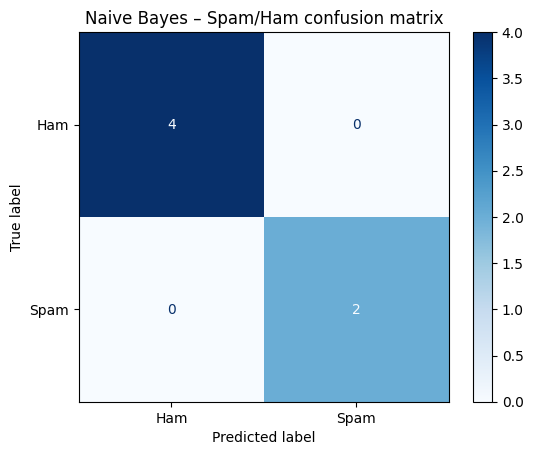

In [6]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    labels=["ham", "spam"],
    display_labels=["Ham", "Spam"],
    cmap="Blues",
    values_format="d"
)
plt.title("Naive Bayes – Spam/Ham confusion matrix")
plt.show()


## 7. Predict a new email and inspect probabilities

Naive Bayes can return class probabilities as well as a predicted label. These probabilities help demonstrate how the model compares Spam and Ham.

The probabilities are model estimates, not guaranteed real-world confidence levels. Their calibration can vary, especially with small or unrepresentative data.


In [7]:
new_messages = [
    "Congratulations claim your free prize now",
    "Please review the project report before our meeting",
    "Free offer waiting for you"
]

predicted_labels = multinomial_model.predict(new_messages)
predicted_probabilities = multinomial_model.predict_proba(new_messages)
classes = multinomial_model.named_steps["nb"].classes_

for message, label, probabilities in zip(
    new_messages, predicted_labels, predicted_probabilities
):
    print("Message:", message)
    print("Predicted class:", label)
    print("Class probabilities:", dict(zip(classes, probabilities.round(3))))
    print("-" * 60)


Message: Congratulations claim your free prize now
Predicted class: spam
Class probabilities: {np.str_('ham'): np.float64(0.001), np.str_('spam'): np.float64(0.999)}
------------------------------------------------------------
Message: Please review the project report before our meeting
Predicted class: ham
Class probabilities: {np.str_('ham'): np.float64(1.0), np.str_('spam'): np.float64(0.0)}
------------------------------------------------------------
Message: Free offer waiting for you
Predicted class: spam
Class probabilities: {np.str_('ham'): np.float64(0.073), np.str_('spam'): np.float64(0.927)}
------------------------------------------------------------


## 8. Laplace smoothing – why do we need it?

Suppose a word appears in a new message but never appeared in Spam messages in the training data. Without smoothing, its estimated likelihood for Spam may be zero.

Because Naive Bayes multiplies feature likelihoods, one zero probability can make the entire class score zero.

**Laplace smoothing** adds a small count (commonly 1) when estimating categorical or word probabilities. In scikit-learn's `MultinomialNB`, the `alpha` parameter controls additive smoothing.

- `alpha=0`: no smoothing (not recommended for ordinary use).
- `alpha=1`: Laplace smoothing.
- Larger alpha: stronger smoothing.

Try different alpha values. With a small classroom dataset, results may vary considerably; focus on the principle rather than treating the score as a benchmark.


In [8]:
alpha_values = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]
alpha_rows = []

for alpha in alpha_values:
    model = Pipeline([
        ("vectorizer", CountVectorizer()),
        ("nb", MultinomialNB(alpha=alpha))
    ])
    model.fit(X_train_text, y_train)
    p = model.predict(X_test_text)
    alpha_rows.append({
        "alpha": alpha,
        "accuracy": accuracy_score(y_test, p),
        "spam_precision": precision_score(y_test, p, pos_label="spam", zero_division=0),
        "spam_recall": recall_score(y_test, p, pos_label="spam", zero_division=0),
        "spam_f1": f1_score(y_test, p, pos_label="spam", zero_division=0)
    })

display(pd.DataFrame(alpha_rows))


,alpha,accuracy,spam_precision,spam_recall,spam_f1
0,0.01,1.0,1.0,1.0,1.0
1,0.10,1.0,1.0,1.0,1.0
2,0.50,1.0,1.0,1.0,1.0
3,1.00,1.0,1.0,1.0,1.0
4,2.00,1.0,1.0,1.0,1.0
5,5.00,1.0,1.0,1.0,1.0


## 9. Bag-of-Words vs TF-IDF

Bag-of-Words represents words using counts. TF-IDF (Term Frequency–Inverse Document Frequency) gives more weight to terms that are frequent in a particular document but less common across the whole collection.

Virtual Labs discusses both Bag-of-Words and TF-IDF as text representations. Multinomial Naive Bayes is commonly used with count features; TF-IDF can also be tried, but raw counts are the straightforward starting point for this experiment.


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("nb", MultinomialNB())
])

tfidf_model.fit(X_train_text, y_train)
tfidf_pred = tfidf_model.predict(X_test_text)

print("Bag-of-Words accuracy:",
      round(accuracy_score(y_test, pred), 3))
print("TF-IDF accuracy:",
      round(accuracy_score(y_test, tfidf_pred), 3))
print("\nTF-IDF classification report:")
print(classification_report(y_test, tfidf_pred, zero_division=0))


Bag-of-Words accuracy: 1.0
TF-IDF accuracy: 1.0

TF-IDF classification report:
              precision    recall  f1-score   support

         ham       1.00      1.00      1.00         4
        spam       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



## 10. Compare Naive Bayes variants

Virtual Labs describes several variants. The choice depends on the type of feature data.

| Variant | Suitable feature type | Example |
|---|---|---|
| MultinomialNB | Discrete counts / term frequencies | Word counts in emails |
| BernoulliNB | Binary presence/absence features | Whether a keyword appears |
| GaussianNB | Continuous numeric features, modelled with a Gaussian distribution | Measurements such as flower dimensions |
| CategoricalNB | Categorical features | Colour, weather, device type |

The following cells demonstrate these variants with suitable data.


### 10A. Bernoulli Naive Bayes – word present or absent

In [10]:
from sklearn.naive_bayes import BernoulliNB

bernoulli_model = Pipeline([
    ("vectorizer", CountVectorizer(binary=True)),
    ("nb", BernoulliNB(alpha=1.0))
])

bernoulli_model.fit(X_train_text, y_train)
bernoulli_pred = bernoulli_model.predict(X_test_text)

print("BernoulliNB accuracy:",
      round(accuracy_score(y_test, bernoulli_pred), 3))
print(classification_report(y_test, bernoulli_pred, zero_division=0))


BernoulliNB accuracy: 1.0
              precision    recall  f1-score   support

         ham       1.00      1.00      1.00         4
        spam       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



### 10B. Gaussian Naive Bayes – continuous numeric features

GaussianNB accuracy: 0.967
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



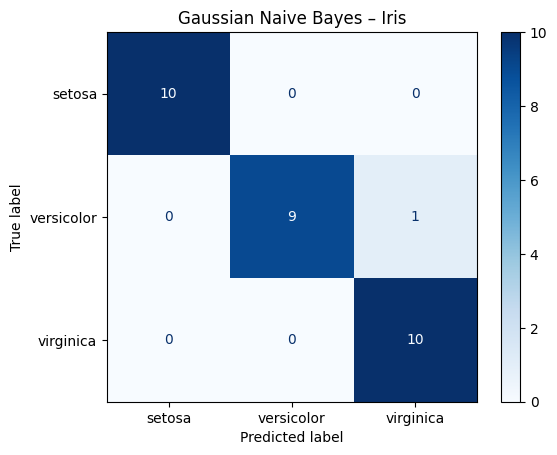

In [11]:
from sklearn.datasets import load_iris
from sklearn.naive_bayes import GaussianNB

iris = load_iris(as_frame=True)
X_iris, y_iris = iris.data, iris.target

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_iris, y_iris,
    test_size=0.20,
    random_state=42,
    stratify=y_iris
)

gaussian_nb = GaussianNB()
gaussian_nb.fit(Xi_train, yi_train)
iris_pred = gaussian_nb.predict(Xi_test)

print("GaussianNB accuracy:",
      round(accuracy_score(yi_test, iris_pred), 3))
print(classification_report(
    yi_test, iris_pred, target_names=iris.target_names
))
ConfusionMatrixDisplay.from_predictions(
    yi_test, iris_pred,
    display_labels=iris.target_names,
    cmap="Blues"
)
plt.title("Gaussian Naive Bayes – Iris")
plt.show()


### 10C. Categorical Naive Bayes – categorical features

In [12]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder

# Small illustrative categorical dataset
weather_data = pd.DataFrame({
    "weather": ["sunny", "sunny", "overcast", "rainy", "rainy",
                "rainy", "overcast", "sunny", "sunny", "rainy",
                "sunny", "overcast"],
    "temperature": ["hot", "hot", "hot", "mild", "cool", "cool",
                    "cool", "mild", "cool", "mild", "mild", "mild"],
    "wind": ["weak", "strong", "weak", "weak", "weak", "strong",
             "strong", "weak", "weak", "weak", "strong", "strong"],
    "play": ["no", "no", "yes", "yes", "yes", "no",
             "yes", "no", "yes", "yes", "yes", "yes"]
})

X_cat = weather_data[["weather", "temperature", "wind"]]
y_cat = weather_data["play"]

encoder = OrdinalEncoder()
X_cat_encoded = encoder.fit_transform(X_cat).astype(int)

cat_nb = CategoricalNB()
cat_nb.fit(X_cat_encoded, y_cat)

new_weather = pd.DataFrame({
    "weather": ["sunny"],
    "temperature": ["cool"],
    "wind": ["strong"]
})
new_weather_encoded = encoder.transform(new_weather).astype(int)

print("Predicted class:", cat_nb.predict(new_weather_encoded)[0])
print("Class probabilities:",
      dict(zip(cat_nb.classes_, cat_nb.predict_proba(new_weather_encoded)[0].round(3))))


Predicted class: no
Class probabilities: {np.str_('no'): np.float64(0.507), np.str_('yes'): np.float64(0.493)}


## 11. Strengths and limitations

### Strengths
- Simple and computationally efficient.
- Often effective for high-dimensional, sparse text data.
- Can perform well with relatively small training datasets.
- Fast to train and predict.

### Limitations
- The conditional independence assumption is often unrealistic.
- Strongly correlated features can affect probability estimates.
- It may not capture complex feature interactions or non-linear relationships.
- Probability estimates should not automatically be interpreted as calibrated confidence.

### Business perspective
For spam detection, a false positive means a legitimate email is marked as spam; a false negative means spam reaches the inbox. The business should decide which error is more costly and evaluate precision and recall accordingly.


## 12. Knowledge check

1. What is a prior probability?
2. What is a posterior probability?
3. What does the naive independence assumption mean?
4. Why can a zero likelihood be a problem?
5. What does Laplace smoothing do?
6. When would you choose MultinomialNB rather than GaussianNB?
7. What is the difference between MultinomialNB and BernoulliNB?
8. Why is Naive Bayes a popular baseline for text classification?
9. In spam detection, what does a false positive mean?
10. Why should the test data not be used to fit the text vectorizer?

### Suggested answers
1. Class probability before observing the message features.
2. Updated class probability after observing the features.
3. Features are treated as conditionally independent given the class.
4. Multiplying likelihoods can make the full class score zero.
5. Adds a small count to avoid zero probability for unseen feature values.
6. MultinomialNB is suitable for word counts or term-frequency features; GaussianNB is for continuous features modelled with Gaussian distributions.
7. MultinomialNB uses counts/frequencies; BernoulliNB uses binary presence/absence.
8. It is fast and handles high-dimensional sparse word representations well.
9. A legitimate email is incorrectly classified as spam.
10. Fitting preprocessing on test data leaks information and makes evaluation optimistic.


## 13. Mini business challenge

A customer-support team wants to classify incoming messages into:
- Billing
- Technical support
- Delivery
- Account access

In groups, discuss:
1. How would you build a labelled training dataset?
2. Would Bag-of-Words or TF-IDF be a useful starting representation?
3. Which Naive Bayes variant would you try first for word counts?
4. What would the cost of misclassifying an urgent account-access message be?
5. Which metrics would you monitor by category?
6. How would you detect vocabulary changes over time?

**Key takeaway:** Naive Bayes combines prior class probabilities with feature likelihoods. Its simplifying independence assumption makes it efficient and useful for text classification, but model choice and evaluation must reflect the data and business costs.
